# 07. Powiaty i mapa upraw (EUCROPMAP) — dane dla biuletynu B1 + B2

Podgląd i kontrola wyników kroku wspólnego `B1_B2/prepare_counties_crops.py` (ten sam kod z `lib/`, tu z wykresami):
1. **Granice powiatów** z GUGiK (WFS PRG, bez konta). Biuletyn robimy tylko dla powiatów ziemskich — miasta na prawach powiatu (numer powiatu w TERYT ≥ 61) odrzuca kod.
2. **Struktura upraw** z mapy EUCROPMAP (JRC, 10 m, lata 2018 i 2022, bez konta). Liczymy udział grup upraw w każdym kwadracie 250 m i z tego: jaki % pól ornych powiatu zajmuje każda grupa oraz ile pikseli MODIS to „czysta” jedna grupa (potrzebne do osobnych krzywych NDVI dla grup upraw).

**Teoria w skrócie.** Piksel NDVI MODIS ma 250 m (ok. 6 ha), a wiele polskich pól jest mniejszych — piksel to często mieszanka upraw. Krzywą NDVI dla konkretnej grupy upraw liczymy więc tylko z pikseli, w których ta grupa ma ≥ 75% powierzchni. EUCROPMAP nie odróżnia ozimin od jarych, więc grupy są przybliżeniem (pszenica, żyto, pszenżyto → „ozime”; jęczmień, owies → „jare”). Rolnicy co roku zmieniają uprawy, więc przypisanie piksela do uprawy obowiązuje tylko w roku mapy; sprawdzamy niżej, czy struktura całego powiatu jest stabilna między 2018 a 2022.

Wymagane: `pip install rasterio geopandas shapely pyarrow matplotlib` oraz `lib/`. Pierwsze uruchomienie czyta ok. 2 × 5,8 mld pikseli 10 m z serwera JRC (kilka minut); wynik (mały GeoTIFF 250 m) zapisuje się w `data/crops/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap

# Katalog główny repo: notatnik może być uruchomiony z notebooks/ albo z głównego folderu
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from lib import boundaries
from lib import eucropmap as ec
from lib import ndvi_tools as nt

DATA = ROOT / "data"
YEARS = (2018, 2022)        # roczniki EUCROPMAP
PURE = 0.75                 # piksel MODIS „czysty” dla grupy, gdy grupa zajmuje >= 75% jego powierzchni
MIN_PURE_PX = 50            # min. liczba czystych pikseli (ok. 300 ha), żeby liczyć krzywą grupy w powiecie
GROUP_COLORS = {"winter_cereals_rapeseed": "#a57000", "spring_cereals": "#e2007c", "maize": "#ffd300",
                "root_crops": "#a800e2", "grassland": "#93cc93", "other_crops": "#00a8e2"}
GROUP_LABELS = {key: label for key, label, _ in ec.GROUPS.values()}

## 1. Powiaty

powiatów: 380 | ziemskich: 314 | miast na prawach powiatu: 66


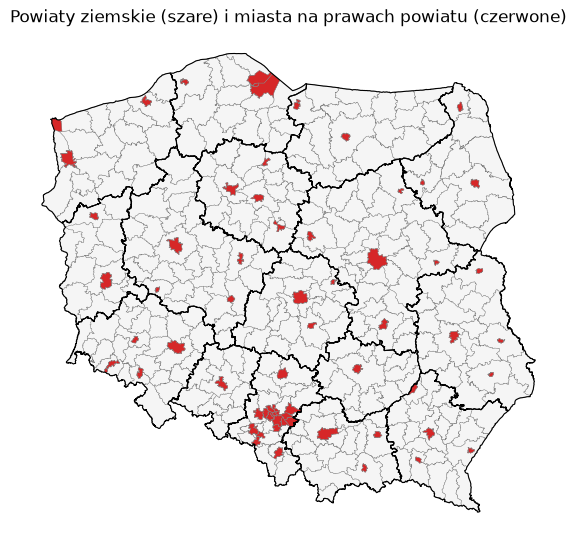

In [2]:
counties = boundaries.load_counties(DATA)
rural = counties[~counties["is_city"]].reset_index(drop=True)
print(f"powiatów: {len(counties)} | ziemskich: {len(rural)} | miast na prawach powiatu: {counties['is_city'].sum()}")

fig, ax = plt.subplots(figsize=(7, 7))
counties.plot(ax=ax, color=np.where(counties["is_city"], "tab:red", "whitesmoke"), edgecolor="grey", linewidth=0.3)
boundaries.load_voivodeships(DATA).boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Powiaty ziemskie (szare) i miasta na prawach powiatu (czerwone)")
ax.set_axis_off()
plt.show()

## 2. EUCROPMAP → udział grup upraw w kwadratach 250 m

`build_group_fractions` czyta mapę 10 m kawałkami prosto z serwera JRC (tylko kawałki nachodzące na Polskę) i od razu liczy udział każdej grupy w kwadracie 250 m (625 małych pikseli). Pełnej mapy 10 m nie zapisujemy. Kolejne uruchomienia biorą gotowy plik.

In [3]:
paths = {y: ec.build_group_fractions(y, counties, DATA) for y in YEARS}
for y, p in paths.items():
    with rasterio.open(p) as src:
        print(y, p.name, "|", src.width, "x", src.height, "px po 250 m |", list(src.descriptions))

2018 eucropmap_2018_groups_250m.tif | 2875 x 2452 px po 250 m | ['winter_cereals_rapeseed', 'spring_cereals', 'maize', 'root_crops', 'grassland', 'other_crops', 'non_crop']
2022 eucropmap_2022_groups_250m.tif | 2875 x 2452 px po 250 m | ['winter_cereals_rapeseed', 'spring_cereals', 'maize', 'root_crops', 'grassland', 'other_crops', 'non_crop']


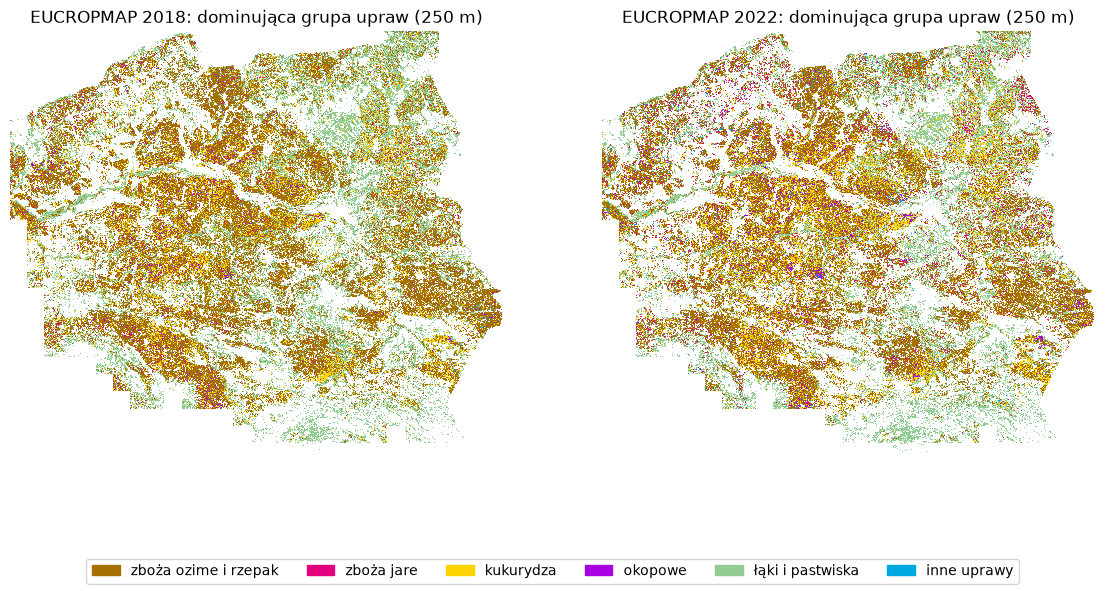

In [4]:
# mapa: dominująca grupa upraw w kwadracie 250 m (tylko tam, gdzie uprawy zajmują >= 50%)
keys = [ec.GROUPS[g][0] for g in sorted(ec.GROUPS)]
fig, axes = plt.subplots(1, len(YEARS), figsize=(7 * len(YEARS), 7))
for ax, y in zip(axes, YEARS):
    with rasterio.open(paths[y]) as src:
        frac = src.read()[: len(keys)]
    dominant = np.where(frac.sum(axis=0) >= 0.5, frac.argmax(axis=0), np.nan)
    ax.imshow(dominant, cmap=ListedColormap([GROUP_COLORS[k] for k in keys]), vmin=-0.5, vmax=len(keys) - 0.5,
              interpolation="nearest")
    ax.set_title(f"EUCROPMAP {y}: dominująca grupa upraw (250 m)")
    ax.set_axis_off()
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[k]) for k in keys]
fig.legend(handles, [GROUP_LABELS[k] for k in keys], loc="lower center", ncol=len(keys))
plt.show()

## 3. Struktura upraw powiatów

`arable_km2` = grunty orne (bez łąk), `share_*_pct` = jaki % pól ornych zajmuje grupa. Łąki podajemy osobno w km² (`grassland_km2`), bo to nie są pola orne.

In [5]:
structure = {}
for y in YEARS:
    s = ec.crop_structure(paths[y], rural)
    structure[y] = rural[["region_id", "name", "voiv_name"]].merge(s, on="region_id")

share_cols = [c for c in structure[2018].columns if c.startswith("share_")]
structure[2018].sort_values("arable_km2", ascending=False).head(10).round(1)

,region_id,name,voiv_name,winter_cereals_rapeseed_km2,spring_cereals_km2,maize_km2,root_crops_km2,grassland_km2,other_crops_km2,arable_km2,share_winter_cereals_rapeseed_pct,share_spring_cereals_pct,share_maize_pct,share_root_crops_pct,share_other_crops_pct
53,0609,powiat lubelski,lubelskie,780.4,72.3,160.9,47.1,146.1,29.4,1090.0,71.6,6.6,14.8,4.3,2.7
45,0601,powiat bialski,lubelskie,646.0,187.6,200.5,4.7,604.5,19.8,1058.6,61.0,17.7,18.9,0.4,1.9
135,1419,powiat płocki,mazowieckie,603.3,75.5,242.5,52.6,215.7,24.9,998.9,60.4,7.6,24.3,5.3,2.5
64,0620,powiat zamojski,lubelskie,655.9,18.7,170.9,48.1,229.5,34.0,927.5,70.7,2.0,18.4,5.2,3.7
285,3021,powiat poznański,wielkopolskie,500.9,59.0,249.3,51.3,234.8,12.5,872.9,57.4,6.8,28.6,5.9,1.4
48,0604,powiat hrubieszowski,lubelskie,573.2,15.1,122.2,90.3,114.3,61.8,862.6,66.5,1.7,14.2,10.5,7.2
32,0407,powiat inowrocławski,kujawsko-pomorskie,397.3,68.6,258.9,74.5,119.9,29.9,829.1,47.9,8.3,31.2,9.0,3.6
43,0418,powiat włocławski,kujawsko-pomorskie,506.8,77.4,160.4,49.4,173.8,20.8,814.9,62.2,9.5,19.7,6.1,2.6
62,0618,powiat tomaszowski,lubelskie,500.7,13.9,150.9,72.8,160.9,60.8,799.0,62.7,1.7,18.9,9.1,7.6
136,1420,powiat płoński,mazowieckie,424.5,37.6,256.6,34.6,183.1,43.8,797.0,53.3,4.7,32.2,4.3,5.5


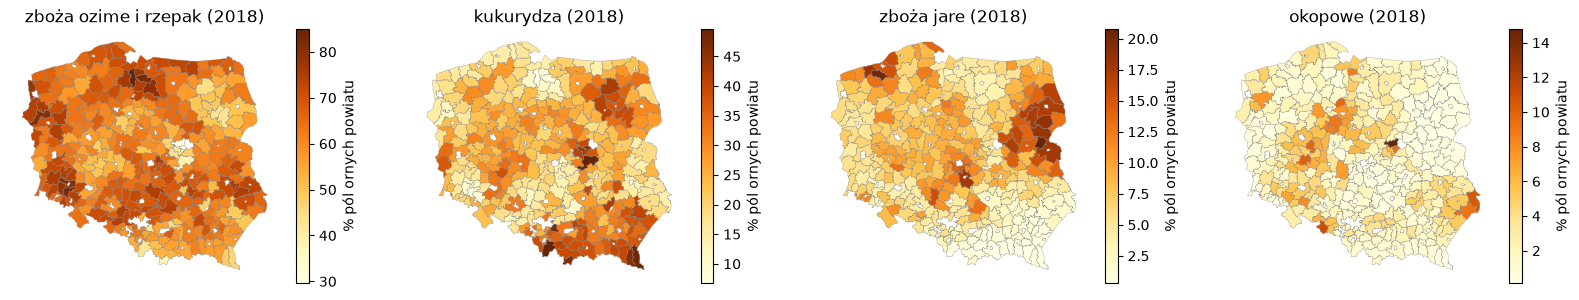

In [6]:
groups_to_map = ["winter_cereals_rapeseed", "maize", "spring_cereals", "root_crops"]
fig, axes = plt.subplots(1, len(groups_to_map), figsize=(5 * len(groups_to_map), 5.5))
for ax, key in zip(axes, groups_to_map):
    d = rural.merge(structure[2018][["region_id", f"share_{key}_pct"]], on="region_id")
    d.plot(column=f"share_{key}_pct", cmap="YlOrBr", legend=True, ax=ax, edgecolor="grey", linewidth=0.2,
           legend_kwds={"shrink": 0.6, "label": "% pól ornych powiatu"})
    ax.set_title(f"{GROUP_LABELS[key]} (2018)")
    ax.set_axis_off()
plt.show()

## 4. Czy struktura upraw powiatu jest stabilna (2018 vs 2022)?

Jeśli udziały grup w powiecie mało się zmieniają między latami, możemy używać struktury z mapy także w innych latach (jako opis powiatu). Przypisanie pojedynczego piksela do uprawy — nie (płodozmian). Uwaga: mapy 2018 i 2022 zrobiono inną metodą (2022 dodatkowo z Sentinel-2), więc część różnic to różnica metody, nie zmiana na polach.

In [7]:
both = structure[2018].merge(structure[2022], on="region_id", suffixes=("_2018", "_2022"))
rows = []
for c in share_cols:
    a, b = both[f"{c}_2018"], both[f"{c}_2022"]
    rows.append({"group": GROUP_LABELS[c.removeprefix("share_").removesuffix("_pct")],
                 "corr_2018_2022": a.corr(b),
                 "mean_abs_diff_pp": (a - b).abs().mean(),
                 "median_abs_diff_pp": (a - b).abs().median()})
stability = pd.DataFrame(rows).round(2)
stability

,group,corr_2018_2022,mean_abs_diff_pp,median_abs_diff_pp
0,zboża ozime i rzepak,0.76,6.78,5.33
1,zboża jare,0.44,5.37,3.52
2,kukurydza,0.68,6.52,5.34
3,okopowe,0.71,2.36,1.57
4,inne uprawy,0.08,1.53,0.96


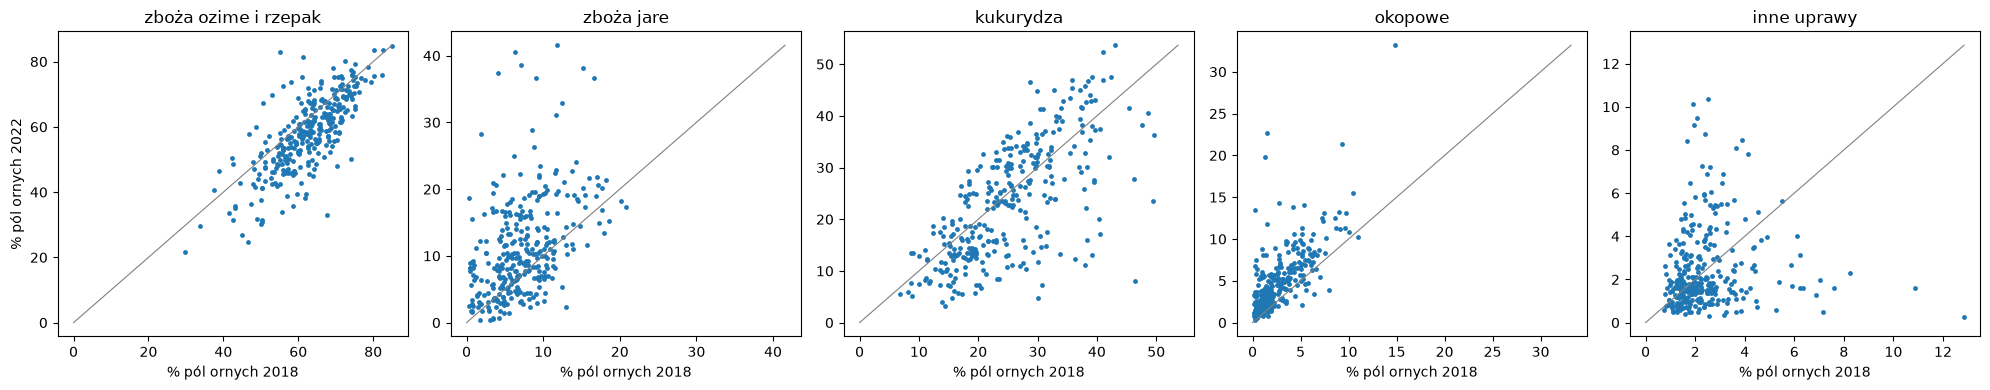

In [8]:
fig, axes = plt.subplots(1, len(share_cols), figsize=(4 * len(share_cols), 4))
for ax, c in zip(axes, share_cols):
    ax.scatter(both[f"{c}_2018"], both[f"{c}_2022"], s=6)
    lim = max(both[f"{c}_2018"].max(), both[f"{c}_2022"].max())
    ax.plot([0, lim], [0, lim], color="grey", lw=0.8)
    ax.set_title(GROUP_LABELS[c.removeprefix("share_").removesuffix("_pct")])
    ax.set_xlabel("% pól ornych 2018")
axes[0].set_ylabel("% pól ornych 2022")
plt.tight_layout()
plt.show()

## 5. Czyste piksele MODIS: gdzie da się liczyć krzywą osobno dla grupy upraw?

Udziały grup przeliczamy na siatkę MODIS (ta sama, z której liczymy NDVI) i liczymy w każdym powiecie piksele z udziałem grupy ≥ 50% i ≥ 75%. Krzywą grupy liczymy tylko w powiatach z co najmniej `MIN_PURE_PX` czystymi pikselami.

In [9]:
grids = nt.modis_tile_grids(2018)
print("kafelki MODIS:", [g[0] for g in grids])
pure = {y: ec.pure_pixel_counts(paths[y], rural, grids, thresholds=(0.5, PURE)) for y in YEARS}

kafelki MODIS: ['h18v03', 'h18v04', 'h19v03', 'h19v04']


In [10]:
summary = (pd.concat(pure, names=["year"]).reset_index(level=0)
             .groupby(["year", "group", "threshold"])["n_pixels"]
             .agg(median="median", counties_ok=lambda s: int((s >= MIN_PURE_PX).sum()))
             .reset_index())
summary["counties_ok_pct"] = (100 * summary["counties_ok"] / len(rural)).round(1)
summary["label"] = summary["group"].map(GROUP_LABELS)
summary.pivot_table(index="label", columns=["year", "threshold"], values="counties_ok_pct")

year                   2018         2022      
threshold              0.50  0.75   0.50  0.75
label                                         
inne uprawy             3.8   0.0   23.9   9.9
kukurydza              86.9  59.2   93.3  73.9
okopowe                29.6  11.1   52.5  27.7
zboża jare             35.0   6.1   67.8  24.8
zboża ozime i rzepak   97.1  90.8   97.1  92.7
łąki i pastwiska      100.0  89.8  100.0  93.0

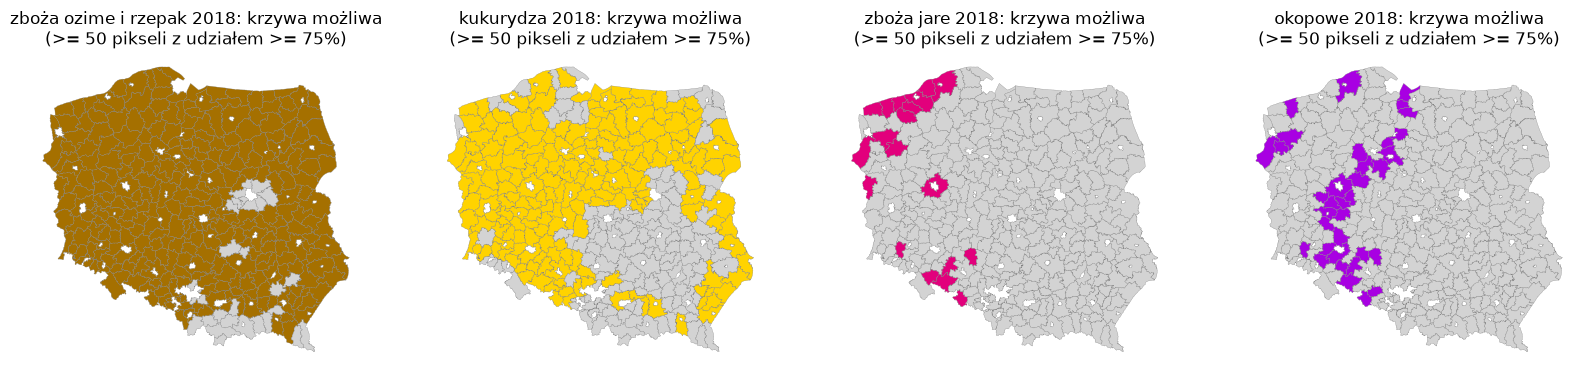

In [11]:
fig, axes = plt.subplots(1, len(groups_to_map), figsize=(5 * len(groups_to_map), 5.5))
for ax, key in zip(axes, groups_to_map):
    sel = pure[2018][(pure[2018]["group"] == key) & (pure[2018]["threshold"] == PURE)]
    d = rural.merge(sel, on="region_id")
    d.plot(color=np.where(d["n_pixels"] >= MIN_PURE_PX, GROUP_COLORS[key], "lightgrey"),
           ax=ax, edgecolor="grey", linewidth=0.2)
    ax.set_title(f"{GROUP_LABELS[key]} 2018: krzywa możliwa\n(>= {MIN_PURE_PX} pikseli z udziałem >= {PURE:.0%})")
    ax.set_axis_off()
plt.show()

## 6. Wnioski (liczone z danych powyżej)

In [12]:
s18 = structure[2018]
print(f"Powiaty ziemskie: {len(rural)}; pola orne łącznie (2018): {s18['arable_km2'].sum():,.0f} km2")
for c in share_cols:
    key = c.removeprefix("share_").removesuffix("_pct")
    share = s18[f"{key}_km2"].sum() / s18["arable_km2"].sum() * 100
    print(f"  {GROUP_LABELS[key]:<22} {share:5.1f}% pól ornych w Polsce")
print("\nStabilność struktury 2018 -> 2022 (średnia różnica udziału w punktach procentowych):")
for _, r in stability.iterrows():
    print(f"  {r['group']:<22} {r['mean_abs_diff_pp']:5.1f} pp (korelacja {r['corr_2018_2022']:.2f})")
print(f"\nPowiaty, w których da się liczyć krzywą grupy (>= {MIN_PURE_PX} pikseli z udziałem >= {PURE:.0%}):")
for y in YEARS:
    ok = summary[(summary["year"] == y) & (summary["threshold"] == PURE)].set_index("label")["counties_ok"]
    print(f"  {y}: " + ", ".join(f"{g}: {n}" for g, n in ok.items()))

Powiaty ziemskie: 314; pola orne łącznie (2018): 105,958 km2
  zboża ozime i rzepak    63.2% pól ornych w Polsce
  zboża jare               7.9% pól ornych w Polsce
  kukurydza               23.5% pól ornych w Polsce
  okopowe                  3.1% pól ornych w Polsce
  inne uprawy              2.2% pól ornych w Polsce

Stabilność struktury 2018 -> 2022 (średnia różnica udziału w punktach procentowych):
  zboża ozime i rzepak     6.8 pp (korelacja 0.76)
  zboża jare               5.4 pp (korelacja 0.44)
  kukurydza                6.5 pp (korelacja 0.68)
  okopowe                  2.4 pp (korelacja 0.71)
  inne uprawy              1.5 pp (korelacja 0.08)

Powiaty, w których da się liczyć krzywą grupy (>= 50 pikseli z udziałem >= 75%):
  2018: łąki i pastwiska: 282, kukurydza: 186, inne uprawy: 0, okopowe: 35, zboża jare: 19, zboża ozime i rzepak: 285
  2022: łąki i pastwiska: 292, kukurydza: 232, inne uprawy: 31, okopowe: 87, zboża jare: 78, zboża ozime i rzepak: 291
